# Modelado y evaluación de un modelo de clasificación: churn de clientes

Pre-entrega de Data Science II (Coderhouse, comisión 90545).

**Objetivo:** entrenar un modelo de clasificación binaria que prediga si un cliente de una empresa de telecomunicaciones se va a dar de baja (*churn*), y evaluarlo con Accuracy, Precision, Recall, F1-Score y matriz de confusión sobre el conjunto de prueba.

**Pasos del notebook:**
1. Carga de datos y diagnóstico de nulos
2. Variable objetivo
3. División en entrenamiento y prueba (80/20)
4. Modelo (regresión logística dentro de un Pipeline)
5. Elección entre variantes con validación cruzada (solo con train)
6. Métricas sobre el conjunto de prueba
7. Justificación de la métrica principal
8. Conclusión para el negocio

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

from churn_utils import (cargar_datos, limpiar_datos, separar_columnas,
                         construir_preprocesador, construir_pipeline)

SEMILLA = 42  # para que los resultados sean siempre los mismos

## 1. Carga de datos

Uso el dataset *Telco Customer Churn* (IBM), que es un dataset clásico de churn: 7043 clientes de una empresa de telecomunicaciones, con datos de su contrato, los servicios que tiene contratados y su facturación. La columna `Churn` dice si el cliente se fue. El CSV está guardado en la carpeta `data/` del repositorio, así que el notebook corre sin internet.

In [2]:
df = cargar_datos()
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Diagnóstico de nulos

Antes de limpiar reviso cuántos nulos tiene cada columna.

In [3]:
print(df.isna().sum())
print()
print("Tipo de TotalCharges:", df["TotalCharges"].dtype)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Tipo de TotalCharges: str


In [4]:
# TotalCharges debería ser numérica pero está como texto: busco por qué
vacios = df[df["TotalCharges"].str.strip() == ""]
print("Filas con TotalCharges vacío:", len(vacios))
vacios[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head()

Filas con TotalCharges vacío: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No


`isna()` no encuentra ningún nulo, pero `TotalCharges` es texto porque hay 11 filas con un espacio en blanco. En todas esas filas `tenure` vale 0, es decir que son clientes recién llegados que todavía no recibieron ninguna factura.

**Decisión:** convierto la columna a número y completo esos 11 casos con 0, que es lo que corresponde (todavía no pagaron nada). Es una constante, no un valor calculado con los datos, así que no genera data leakage. También paso `Churn` de "Yes"/"No" a 1/0 y elimino `customerID`, que es solo un identificador.

In [5]:
df = limpiar_datos(df)
print("Nulos después de limpiar:", df.isna().sum().sum())
print("Tipo de TotalCharges:", df["TotalCharges"].dtype)

Nulos después de limpiar: 0
Tipo de TotalCharges: float64


## 2. Variable objetivo

Reviso cuántos clientes se fueron. Esto es importante porque define qué tan engañosa puede ser la Accuracy.

Porcentaje de clientes (0 = se quedó, 1 = se fue):
Churn
0    73.5
1    26.5
Name: proportion, dtype: float64

Accuracy de un modelo que siempre predice 'se queda': 0.735


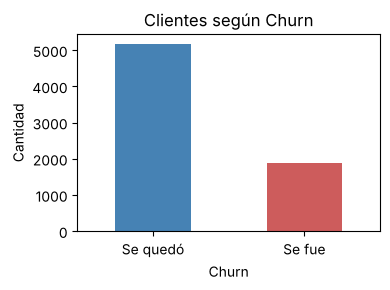

In [6]:
porcentaje = df["Churn"].value_counts(normalize=True).mul(100).round(1)
print("Porcentaje de clientes (0 = se quedó, 1 = se fue):")
print(porcentaje)

# si el modelo dijera siempre "no se va", acertaría este porcentaje
accuracy_base = porcentaje[0] / 100
print(f"\nAccuracy de un modelo que siempre predice 'se queda': {accuracy_base:.3f}")

df["Churn"].value_counts().rename({0: "Se quedó", 1: "Se fue"}).plot(
    kind="bar", color=["steelblue", "indianred"], figsize=(4, 3))
plt.title("Clientes según Churn")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Hay **desbalance de clases**: aproximadamente 1 de cada 4 clientes se fue. Un modelo que no aprendiera nada y dijera siempre "se queda" tendría una Accuracy de más de 0.73, pero no detectaría ni una sola baja. Por eso no alcanza con mirar la Accuracy.

## 3. División en entrenamiento y prueba (80/20)

Divido los datos **antes** de ajustar cualquier cosa (escalador, codificador o modelo), para que el conjunto de prueba no influya en el entrenamiento. Uso `stratify=y` para que la proporción de bajas sea la misma en los dos conjuntos y `random_state` para poder repetir la división.

In [7]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print(f"Proporción de churn en train: {y_train.mean():.3f}")
print(f"Proporción de churn en test:  {y_test.mean():.3f}")

Entrenamiento: (5634, 19) | Prueba: (1409, 19)
Proporción de churn en train: 0.265
Proporción de churn en test:  0.265


## 4. Modelo: regresión logística dentro de un Pipeline

Elijo **regresión logística** porque es un modelo simple de clasificación binaria y fácil de interpretar. Armo un `Pipeline` que incluye el preprocesamiento:

- columnas numéricas: `StandardScaler`
- columnas categóricas: `OneHotEncoder(handle_unknown="ignore")`
- modelo: `LogisticRegression`

Con todo dentro del `Pipeline`, el escalador y el codificador se ajustan solo con el conjunto de entrenamiento y después se aplican igual al de prueba.

Voy a comparar dos variantes de la regresión logística:
- **Base:** sin ningún ajuste.
- **Balanceada:** con `class_weight="balanced"`, que le da más importancia a los errores sobre la clase minoritaria (los clientes que se van).

In [8]:
numericas, categoricas = separar_columnas(X_train)
print("Columnas numéricas:", numericas)
print("Cantidad de columnas categóricas:", len(categoricas))

modelo_base = construir_pipeline(numericas, categoricas)
modelo_balanceado = construir_pipeline(numericas, categoricas, class_weight="balanced")
modelo_balanceado

Columnas numéricas: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Cantidad de columnas categóricas: 15


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, d

## 5. Elección de la variante con validación cruzada (solo con train)

Para decidir entre variantes no quiero usar el conjunto de prueba, porque lo tengo que reservar para la evaluación final. Entonces comparo con validación cruzada estratificada de 5 folds **sobre el conjunto de entrenamiento**. Además de las dos regresiones logísticas incluyo un Random Forest balanceado, para ver si un modelo más complejo mejora. Comparo Recall y F1 (la razón de usar Recall se explica en la sección 7).

In [9]:
candidatos = {
    "Regresión logística base": modelo_base,
    "Regresión logística balanceada": modelo_balanceado,
    "Random Forest balanceado": Pipeline([
        ("preprocesador", construir_preprocesador(numericas, categoricas)),
        ("modelo", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                          class_weight="balanced", random_state=SEMILLA)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, modelo in candidatos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=["recall", "f1"])
    filas.append({"Modelo": nombre,
                  "Recall (promedio)": r["test_recall"].mean(),
                  "Recall (desvío)": r["test_recall"].std(),
                  "F1 (promedio)": r["test_f1"].mean()})

pd.DataFrame(filas).set_index("Modelo").round(3)

,Recall (promedio),Recall (desvío),F1 (promedio)
Modelo,,,
Regresión logística base,0.543,0.041,0.592
Regresión logística balanceada,0.801,0.038,0.628
Random Forest balanceado,0.764,0.028,0.632


La regresión logística balanceada tiene el mejor Recall en validación cruzada y un F1 parecido al del Random Forest, y además es más simple. Por eso la elijo como **modelo final**. Mantengo también la versión base para comparar qué cambia al balancear las clases.

In [10]:
modelo_base.fit(X_train, y_train)
modelo_balanceado.fit(X_train, y_train)
print("Modelos entrenados con", len(X_train), "clientes")

Modelos entrenados con 5634 clientes


## 6. Métricas sobre el conjunto de prueba

Ahora sí uso el conjunto de prueba, que el modelo nunca vio. Calculo Accuracy, Precision, Recall y F1-Score. Incluyo como referencia el modelo que siempre dice "se queda".

In [11]:
def calcular_metricas(y_real, y_pred):
    return {"Accuracy": accuracy_score(y_real, y_pred),
            "Precision": precision_score(y_real, y_pred, zero_division=0),
            "Recall": recall_score(y_real, y_pred),
            "F1-Score": f1_score(y_real, y_pred)}

pred_base = modelo_base.predict(X_test)
pred_balanceado = modelo_balanceado.predict(X_test)
pred_siempre_no = [0] * len(y_test)

tabla = pd.DataFrame({
    "Siempre 'se queda'": calcular_metricas(y_test, pred_siempre_no),
    "Regresión logística base": calcular_metricas(y_test, pred_base),
    "Regresión logística balanceada (final)": calcular_metricas(y_test, pred_balanceado),
}).T.round(3)
tabla

,Accuracy,Precision,Recall,F1-Score
Siempre 'se queda',0.735,0.000,0.000,0.000
Regresión logística base,0.806,0.657,0.559,0.604
Regresión logística balanceada (final),0.738,0.504,0.783,0.614


In [12]:
print("Reporte de clasificación del modelo final (conjunto de prueba):")
print(classification_report(y_test, pred_balanceado,
                            target_names=["Se quedó", "Se fue"]))

Reporte de clasificación del modelo final (conjunto de prueba):
              precision    recall  f1-score   support

    Se quedó       0.90      0.72      0.80      1035
      Se fue       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



### Matriz de confusión

Filas = valor real, columnas = predicción. Abajo a la izquierda están los **falsos negativos** (clientes que se iban y el modelo no avisó) y arriba a la derecha los **falsos positivos** (clientes que se quedaban pero el modelo marcó como bajas).

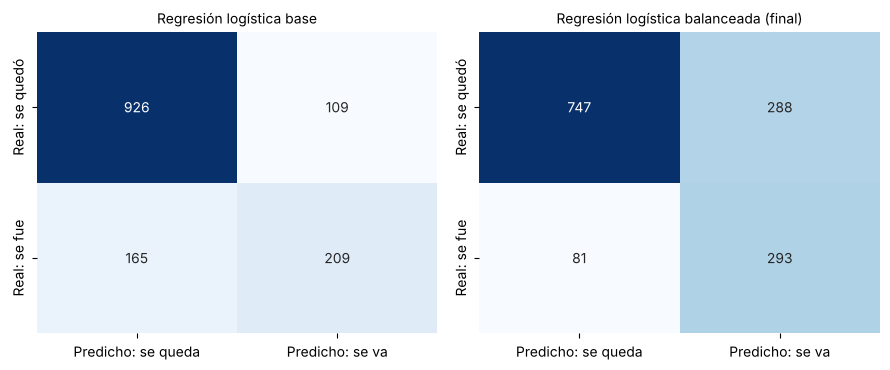

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(9, 3.8))
for eje, pred, titulo in [(ejes[0], pred_base, "Regresión logística base"),
                          (ejes[1], pred_balanceado, "Regresión logística balanceada (final)")]:
    matriz = confusion_matrix(y_test, pred)
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eje,
                xticklabels=["Predicho: se queda", "Predicho: se va"],
                yticklabels=["Real: se quedó", "Real: se fue"])
    eje.set_title(titulo, fontsize=10)
plt.tight_layout()
plt.show()

In [14]:
# Lectura de la matriz del modelo final, con los números calculados
vn, fp, fn, vp = confusion_matrix(y_test, pred_balanceado).ravel()
print(f"Clientes que realmente se fueron en test: {vp + fn}")
print(f"  - el modelo detectó {vp} (verdaderos positivos)  -> Recall = {vp / (vp + fn):.3f}")
print(f"  - el modelo NO detectó {fn} (falsos negativos)")
print(f"Clientes marcados como 'se va': {vp + fp}")
print(f"  - {vp} realmente se iban y {fp} en realidad se quedaban (falsos positivos)")
print(f"  - Precision = {vp / (vp + fp):.3f}")

Clientes que realmente se fueron en test: 374
  - el modelo detectó 293 (verdaderos positivos)  -> Recall = 0.783
  - el modelo NO detectó 81 (falsos negativos)
Clientes marcados como 'se va': 581
  - 293 realmente se iban y 288 en realidad se quedaban (falsos positivos)
  - Precision = 0.504


## 7. ¿Qué métrica es la más importante para churn?

**La métrica más importante es el Recall** (la proporción de clientes que realmente se van y que el modelo logra detectar).

**Por qué, según el costo de los errores:**

- Un **falso negativo** es un cliente que se va y el modelo no lo detectó. La empresa no hace nada, y pierde todos los ingresos futuros de ese cliente. Además, conseguir un cliente nuevo suele costar más que retener a uno existente.
- Un **falso positivo** es un cliente que se iba a quedar pero el modelo marcó como baja. La consecuencia es que la empresa le ofrece una acción de retención (por ejemplo un descuento o un llamado) que no hacía falta. Tiene un costo, pero es acotado y mucho menor que perder al cliente.

Como un falso negativo cuesta bastante más que un falso positivo, conviene un modelo que deje pasar la menor cantidad posible de clientes que se van, aunque eso implique más falsas alarmas. Eso es maximizar el Recall.

**Por qué no las otras:**
- La **Accuracy** engaña con clases desbalanceadas: el modelo que siempre dice "se queda" tiene más de 0.73 y no sirve para nada.
- La **Precision** también importa, pero como control: si fuera muy baja, la campaña de retención se gastaría en muchos clientes que no la necesitaban. Por eso miro también el **F1-Score**, que combina Precision y Recall, para no subir el Recall a cualquier costo.

### Un ejemplo con costos (supuestos míos)

Para ver qué tanto pesan los falsos negativos hago un cálculo con costos **supuestos** (no son datos de la empresa, son valores de ejemplo que se pueden cambiar):

- Un cliente que se va representa una pérdida de **12 meses** de su cargo mensual promedio.
- Una acción de retención cuesta un **descuento del 15% durante 12 meses** sobre el cargo mensual promedio de los clientes que se quedan.
- Simplificación: solo cuento el costo de los errores (falsos negativos y falsos positivos) y no el de las acciones sobre los aciertos.

In [15]:
cargo_se_fue = X_train.loc[y_train == 1, "MonthlyCharges"].mean()
cargo_se_queda = X_train.loc[y_train == 0, "MonthlyCharges"].mean()

costo_fn = cargo_se_fue * 12            # ingreso perdido
costo_fp = cargo_se_queda * 12 * 0.15   # descuento innecesario
print(f"Costo supuesto de un falso negativo: {costo_fn:,.0f}")
print(f"Costo supuesto de un falso positivo: {costo_fp:,.0f}")
print(f"Un falso negativo cuesta unas {costo_fn / costo_fp:.1f} veces más que un falso positivo\n")

def costo_total(pred):
    _, fp, fn, _ = confusion_matrix(y_test, pred).ravel()
    return fn * costo_fn + fp * costo_fp

costos = pd.Series({
    "Sin modelo (no se detecta a nadie)": (y_test == 1).sum() * costo_fn,
    "Regresión logística base": costo_total(pred_base),
    "Regresión logística balanceada (final)": costo_total(pred_balanceado),
}, name="Costo total de errores")
costos.round(0).map("{:,.0f}".format)

Costo supuesto de un falso negativo: 898
Costo supuesto de un falso positivo: 110
Un falso negativo cuesta unas 8.1 veces más que un falso positivo



Sin modelo (no se detecta a nadie)        335,972
Regresión logística base                  160,259
Regresión logística balanceada (final)    104,564
Name: Costo total de errores, dtype: str

Con estos supuestos, el modelo balanceado tiene un costo total de errores menor que el modelo base, aunque su Accuracy sea más baja. Es el mismo punto de la sección anterior: para el negocio importa más detectar a los clientes que se van que acertar en la mayoría de los casos.

## 8. Conclusión para el negocio

- El modelo final es una regresión logística con `class_weight="balanced"`. Sobre el conjunto de prueba **detecta cerca de 8 de cada 10 clientes que se van** (Recall alrededor de 0.78), frente a poco más de 5 de cada 10 del modelo base.
- El costo de esa mejora es una **Precision cercana a 0.5**: aproximadamente la mitad de los clientes que marca como "en riesgo" en realidad se iban a quedar. Y la Accuracy baja respecto del modelo base, pero eso no es un problema porque la Accuracy no es la métrica que importa acá.
- Para la empresa, esto significa que conviene usar el modelo para armar una lista de clientes en riesgo y ofrecerles una acción de retención **barata** (por ejemplo un descuento o un llamado). Mientras la acción cueste mucho menos que perder al cliente, el modelo se paga aun con muchas falsas alarmas. Si la acción fuera cara, habría que subir el umbral para mejorar la Precision.
- Con los costos supuestos, los falsos negativos pesan varias veces más que los falsos positivos, lo que respalda haber elegido el Recall como métrica principal.

**Limitaciones y posibles mejoras:**
- Usé una sola división train/test y el umbral de decisión por defecto (0.5). Se podría ajustar el umbral con una curva Precision-Recall.
- Los costos del ejemplo son supuestos; con los costos reales de la empresa la conclusión podría cambiar.
- Se podrían probar modelos más complejos (Gradient Boosting) con más ajuste de hiperparámetros.